In [1]:
import flowkit as fk
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pathlib
import pandas as pd
import seaborn as sns

In [2]:

# Gate cut-offs for the FlowCAP-I HSCT panel (0-1023 scale), defined once and used everywhere
CUTOFFS = {"pi_cutoff": 700, "cd45_2_cutoff": 550, "cd45_1_cutoff": 450, "mac1_cutoff": 500}


# ---------- Reading files ----------

def inspect_fcs_file(filepath, verbose=False):
    """Load an FCS file. Returns the FlowKit sample and its raw data as a DataFrame."""
    sample = fk.Sample(filepath)
    df_sample = sample.as_dataframe(source='raw', col_multi_index=False)
    if verbose:
        metadata = sample.metadata
        print(f"Total events: {sample.event_count}")
        print(f"PNN labels: {sample.pnn_labels}")
        print(f"PNS labels: {sample.pns_labels}")
        print(f"Instrument (cyt): {metadata.get('cyt')}")
        print(f"Date: {metadata.get('date')}")
        print(f"System (sys): {metadata.get('sys')}")
    return sample, df_sample


def check_spillover_matrix(sample):
    """Return any metadata keys that look like a compensation (spillover) matrix."""
    spill_keys = [k for k in sample.metadata if "spill" in k.lower() or "comp" in k.lower()]
    if spill_keys:
        print("Spillover matrix found")
    else:
        print("No spillover matrix found. Compensation not applied.")
    return spill_keys


def asinh_transformation(sample):
    """Arcsinh transform for linear-scale fluorescence (used for the Attune file in Week 1).
    param_t is the top of that file's measurement range. Not used for the HSCT files,
    which are already log-scaled (0-1023)."""
    asinh_xform = fk.transforms.AsinhTransform(param_t=16777216.0, param_m=4.0, param_a=0.0)
    sample.apply_transform(asinh_xform)
    return sample.as_dataframe(source='xform', col_multi_index=False)


# ---------- Plotting ----------

def plot_scatter(df_sample, x_name, y_name):
    """Plain scatter plot of two channels."""
    plt.scatter(df_sample[x_name], df_sample[y_name], s=1, alpha=0.5)
    plt.xlabel(x_name)
    plt.ylabel(y_name)
    plt.title(f"Scatter plot: {x_name} vs {y_name}")
    plt.show()


def plot_density(df_sample, x_name, y_name, value_range=None):
    """2D density plot with a log colour scale. value_range, e.g. [[0, 1023], [0, 1023]];
    None uses the full range of the data."""
    plt.hist2d(df_sample[x_name], df_sample[y_name], range=value_range, bins=256, norm=LogNorm())
    plt.xlabel(x_name)
    plt.ylabel(y_name)
    plt.title(f"Density plot: {x_name} vs {y_name}")
    plt.show()


def plot_histogram(df_sample, num_col):
    """Histogram of one channel: 256 bins over 0-1023, log-scaled counts."""
    sns.histplot(data=df_sample, x=num_col, bins=256, binrange=(0, 1024), kde=False)
    plt.title(f'Distribution of {num_col}')
    plt.yscale("log")
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.show()


# ---------- Gating ----------

def pct(part, parent):
    """Percentage of part within parent; NaN if the parent is empty."""
    if len(parent) == 0:
        return np.nan
    return 100 * len(part) / len(parent)


def apply_gating(df_sample, pi_cutoff, cd45_2_cutoff, cd45_1_cutoff, mac1_cutoff):
    """Gate one sample and return counts and percentages for every population."""
    # Live / dead
    live = df_sample[df_sample["FL3-H"] < pi_cutoff]
    live_percent = pct(live, df_sample)

    # Recipient: CD45.2-high
    recipient = live[live["FL4-H"] >= cd45_2_cutoff]
    recipient_percent = pct(recipient, live)

    # CD45.2-low, split by CD45.1 into donor and CD45-negative
    cd45_low = live[live["FL4-H"] < cd45_2_cutoff]
    donor = cd45_low[cd45_low["FL1-H"] >= cd45_1_cutoff]
    donor_percent = pct(donor, live)
    cd45_neg = cd45_low[cd45_low["FL1-H"] < cd45_1_cutoff]
    cd45_neg_percent = pct(cd45_neg, live)
    assert len(donor) + len(cd45_neg) == len(cd45_low)
    assert len(recipient) + len(donor) + len(cd45_neg) == len(live)

    # Mac1 within recipient
    mac1_pos_recipient = recipient[recipient["FL2-H"] >= mac1_cutoff]
    mac1_neg_recipient = recipient[recipient["FL2-H"] < mac1_cutoff]
    mac1_pos_recipient_percent = pct(mac1_pos_recipient, recipient)
    assert len(mac1_pos_recipient) + len(mac1_neg_recipient) == len(recipient)

    # Mac1 within donor
    mac1_pos_donor = donor[donor["FL2-H"] >= mac1_cutoff]
    mac1_neg_donor = donor[donor["FL2-H"] < mac1_cutoff]
    mac1_pos_donor_percent = pct(mac1_pos_donor, donor)
    assert len(mac1_pos_donor) + len(mac1_neg_donor) == len(donor)

    # Donor share of all myeloid cells (donor myeloid chimerism)
    all_mac1_pos = len(mac1_pos_recipient) + len(mac1_pos_donor)
    donor_myeloid_chimerism = np.nan if all_mac1_pos == 0 else 100 * len(mac1_pos_donor) / all_mac1_pos

    summary = {"events": len(df_sample),
               "live": len(live),
               "live_pct": live_percent,
               "recipient": len(recipient),
               "recipient_pct": recipient_percent,
               "donor": len(donor),
               "donor_pct": donor_percent,
               "cd45_neg": len(cd45_neg),
               "cd45_neg_pct": cd45_neg_percent,
               "mac1_pos_recipient": len(mac1_pos_recipient),
               "mac1_neg_recipient": len(mac1_neg_recipient),
               "mac1_pos_recipient_pct": mac1_pos_recipient_percent,
               "mac1_pos_donor": len(mac1_pos_donor),
               "mac1_neg_donor": len(mac1_neg_donor),
               "mac1_pos_donor_pct": mac1_pos_donor_percent,
               "donor_myeloid_chimerism_pct": donor_myeloid_chimerism,
               "pi_cutoff": pi_cutoff,
               "cd45_2_cutoff": cd45_2_cutoff,
               "cd45_1_cutoff": cd45_1_cutoff,
               "mac1_cutoff": mac1_cutoff
               }
    return summary


def assign_labels(df_sample, pi_cutoff, cd45_2_cutoff, cd45_1_cutoff, mac1_cutoff):
    """Give every event the name of the group it falls into, using the same gates as apply_gating."""
    dead = df_sample["FL3-H"] >= pi_cutoff
    recipient = ~dead & (df_sample["FL4-H"] >= cd45_2_cutoff)
    donor = ~dead & (df_sample["FL4-H"] < cd45_2_cutoff) & (df_sample["FL1-H"] >= cd45_1_cutoff)
    cd45_neg = ~dead & (df_sample["FL4-H"] < cd45_2_cutoff) & (df_sample["FL1-H"] < cd45_1_cutoff)
    mac1_pos = df_sample["FL2-H"] >= mac1_cutoff

    conditions = [dead,
                  recipient & mac1_pos, recipient & ~mac1_pos,
                  donor & mac1_pos, donor & ~mac1_pos,
                  cd45_neg]
    names = ["dead", "recipient Mac1+", "recipient Mac1-",
             "donor Mac1+", "donor Mac1-", "CD45-negative"]
    return np.select(conditions, names, default="unassigned")


def create_table(folder="data/FlowCAP-I HSCT", out_file="results/hsct_gating_summary.csv", cutoffs=CUTOFFS):
    """Gate every FCS file in a folder with the same cut-offs and save one row per file."""
    sorted_files = sorted(pathlib.Path(folder).glob("*.fcs"))
    all_summaries = []
    for file in sorted_files:
        _, temp_df = inspect_fcs_file(file)
        temp_summary = apply_gating(temp_df, **cutoffs)
        temp_summary["file"] = file.name
        all_summaries.append(temp_summary)

    table_df = pd.DataFrame(all_summaries)
    table_df = table_df[["file"] + [c for c in table_df.columns if c != "file"]]   # file name as first column
    table_df.to_csv(out_file, index=False)
    return table_df


# ---------- Validation ----------

def score_crosstab(tab, min_events=10):
    """For each expert class (except the catch-all class 0), find the group of mine
    that overlaps it most, then calculate precision, recall and F-measure."""
    rows = []
    for expert_class in tab.columns:
        if expert_class == 0:                      # class 0 = experts' "everything else"
            continue
        column = tab[expert_class]                 # how my groups are spread across this expert class
        expert_total = column.sum()                # all cells the experts put in this class

        best_group = column.idxmax()               # my group with the most cells in this class
        both = column[best_group]                  # cells we both put in this population
        my_total = tab.loc[best_group].sum()       # all cells I put in my matched group

        precision = both / my_total                # of my cells, share the experts agree with
        recall = both / expert_total               # of the experts' cells, share I found
        f_measure = 2 * precision * recall / (precision + recall)

        rows.append({
            "expert_class": expert_class,
            "my_group": best_group,
            "expert_cells": int(expert_total),
            "precision": precision,
            "recall": recall,
            "f_measure": f_measure,
            "note": "too few cells to score" if expert_total < min_events else "",
        })
    return pd.DataFrame(rows)

KS_TO_FL = {"FITC.CD45.1": "FL1-H", "PE.Ly65Mac1": "FL2-H",
            "PI.LiveDead": "FL3-H", "APC.CD45.2": "FL4-H"}

def validate_against_labels(labels_csv, folder, subject_to_file, cutoffs):
    """Attach the ks expert labels to each matching FCS file, label every event with
    my gates, and score the agreement file by file."""
    fl_cols = list(KS_TO_FL.values())
    author_df = pd.read_csv(labels_csv).rename(columns=KS_TO_FL)

    all_scores = []
    for subject, file_name in subject_to_file.items():
        _, df = inspect_fcs_file(f"{folder}/{file_name}")
        subject_rows = author_df[author_df["subject"] == subject].reset_index(drop=True)

        assert len(subject_rows) == len(df), f"{file_name}: different number of events"
        assert np.allclose(subject_rows[fl_cols].to_numpy(), df[fl_cols].to_numpy()), \
            f"{file_name}: values don't match"

        df["expert_label"] = subject_rows["label"].to_numpy()
        df["my_label"] = assign_labels(df, **cutoffs)

        tab = pd.crosstab(df["my_label"], df["expert_label"])
        scores = score_crosstab(tab)
        scores.insert(0, "file", file_name)
        all_scores.append(scores)

    return pd.concat(all_scores, ignore_index=True)

Total events: 22188
PNN labels: ['Event', 'Time', 'FSC-A', 'SSC-A', 'BL1-A', 'BL2-A', 'BL3-A', 'VL1-A', 'VL2-A', 'VL3-A', 'FSC-H', 'SSC-H', 'BL1-H', 'BL2-H', 'BL3-H', 'VL1-H', 'VL2-H', 'VL3-H', 'FSC-W', 'SSC-W', 'BL1-W', 'BL2-W', 'BL3-W', 'VL1-W', 'VL2-W', 'VL3-W']
PNS labels: ['Event', 'Time', 'FSC-A', 'SSC-A', 'BL1-A', 'BL2-A', 'BL3-A', 'VL1-A', 'VL2-A', 'VL3-A', 'FSC-H', 'SSC-H', 'BL1-H', 'BL2-H', 'BL3-H', 'VL1-H', 'VL2-H', 'VL3-H', 'FSC-W', 'SSC-W', 'BL1-W', 'BL2-W', 'BL3-W', 'VL1-W', 'VL2-W', 'VL3-W']
Instrument (cyt): Attune Cytometric Software v1.0
Date: 09-May-2010
System (sys): Microsoft Windows NT 5.1.2600 Service Pack 3
No spillover matrix found. Compensation not applied.


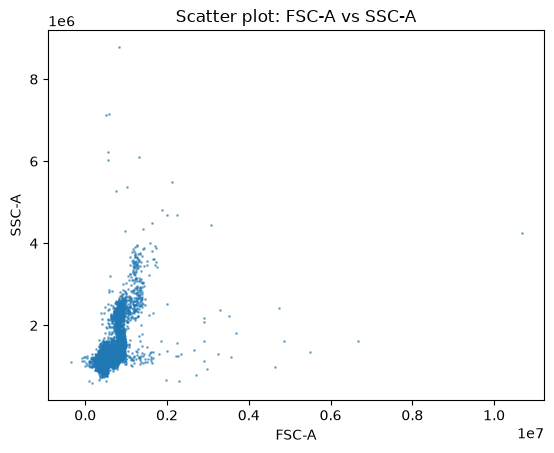

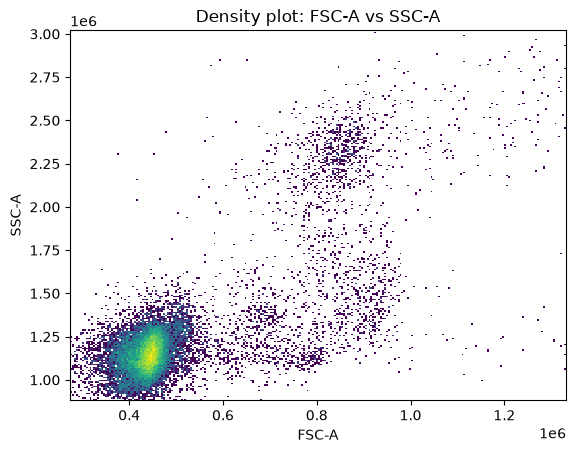

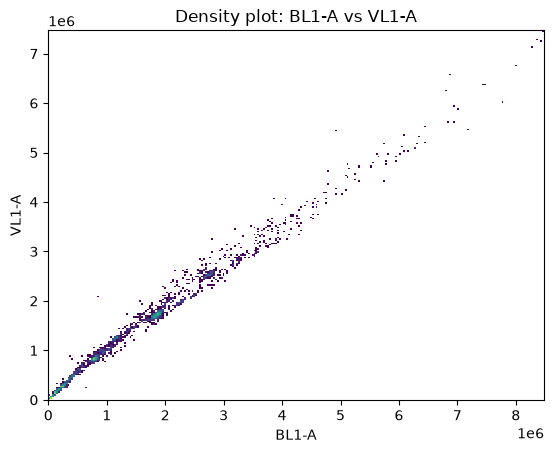

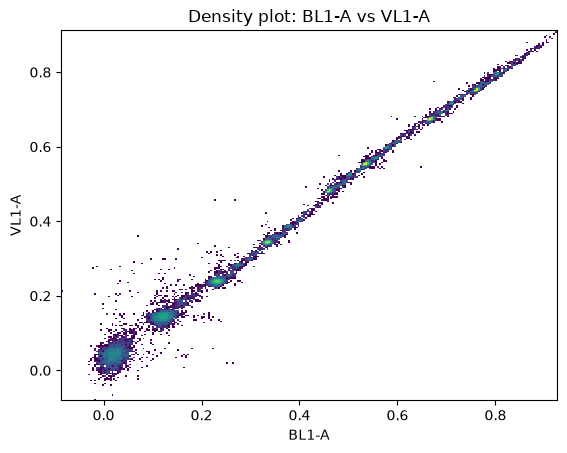

In [3]:
#Week 1 work with experimental file from Attune
file_location = "data/Applied Biosystems - Attune.fcs"
attune_sample, attune_df = inspect_fcs_file(file_location, verbose=True)
check_spillover_matrix(attune_sample)
plot_scatter(attune_df, 'FSC-A', 'SSC-A')

x_lo, x_hi = np.percentile(attune_df["FSC-A"], [0.5, 99.5])
y_lo, y_hi = np.percentile(attune_df["SSC-A"], [0.5, 99.5])
plot_density(attune_df, 'FSC-A', 'SSC-A', value_range=[[x_lo, x_hi], [y_lo, y_hi]] )

transformed_df = asinh_transformation(attune_sample)
plot_density(attune_df, 'BL1-A', 'VL1-A')
plot_density(transformed_df, 'BL1-A', 'VL1-A')


Total events: 9936
PNN labels: ['FSC-H', 'SSC-H', 'FL1-H', 'FL2-H', 'FL3-H', 'FL4-H']
PNS labels: ['', '', '', '', '', '']
Instrument (cyt): None
Date: None
System (sys): None
No spillover matrix found. Compensation not applied.


,FSC-H,SSC-H,FL1-H,FL2-H,FL3-H,FL4-H
count,9936.000000,9936.00000,9936.000000,9936.000000,9936.000000,9936.000000
mean,373.607890,238.09068,142.802637,149.167572,137.338768,726.287037
std,69.559614,130.06709,82.408112,224.378838,162.223709,98.651370
min,236.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,329.000000,143.00000,86.000000,0.000000,0.000000,724.000000
50%,364.000000,198.00000,152.000000,75.000000,86.000000,747.000000
75%,403.000000,302.00000,203.000000,196.000000,213.000000,766.000000
max,818.000000,825.00000,1023.000000,1023.000000,1023.000000,1023.000000


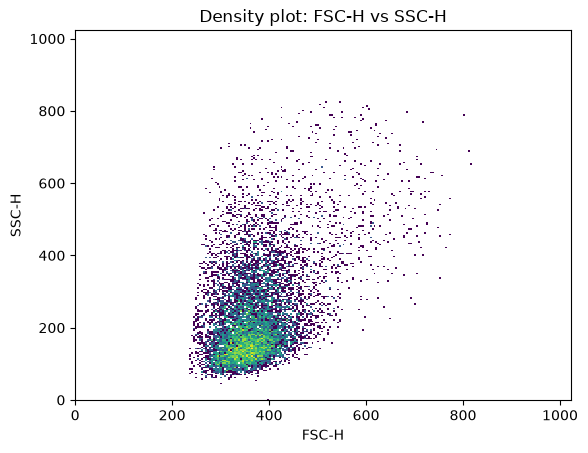

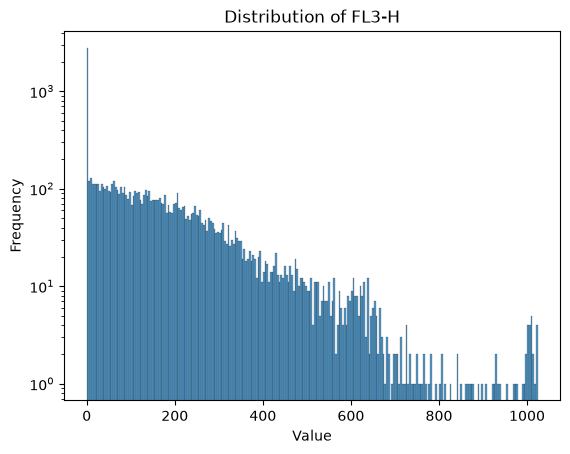

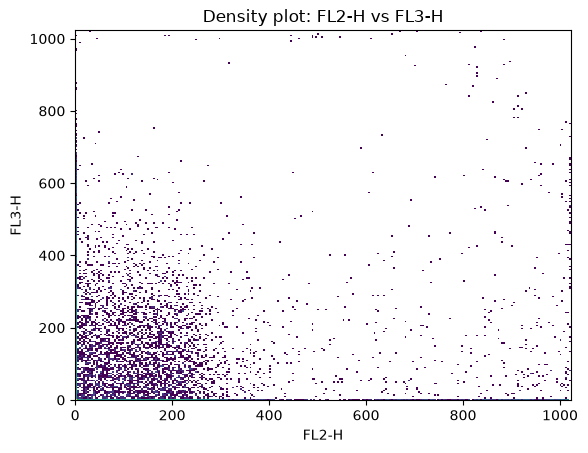

PI cut-off 600: 9721 live cells
PI cut-off 700: 9854 live cells
PI cut-off 800: 9886 live cells
PI cut-off 900: 9901 live cells


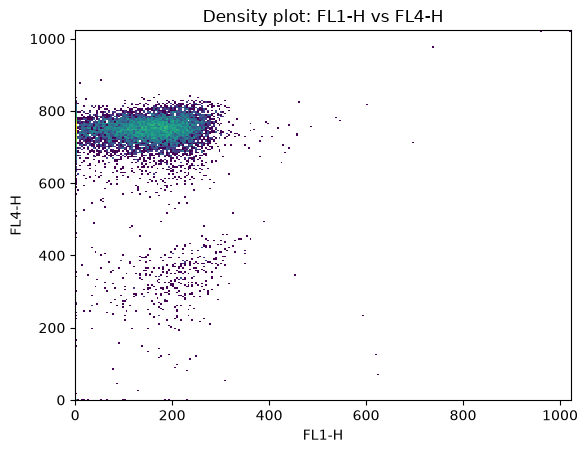

005.fcs


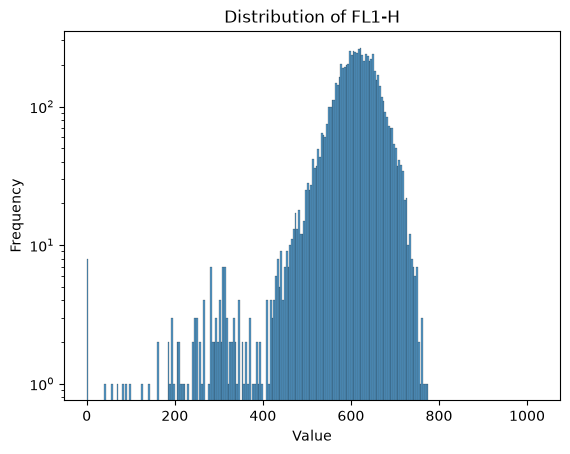

022.fcs


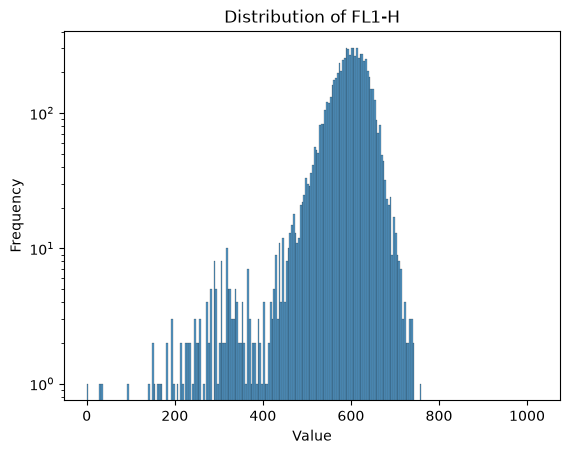

025.fcs


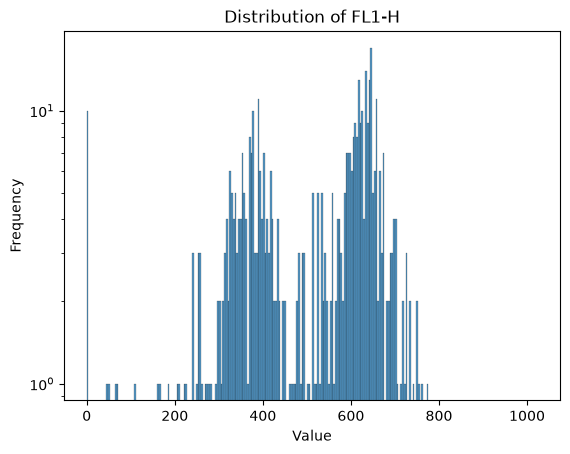

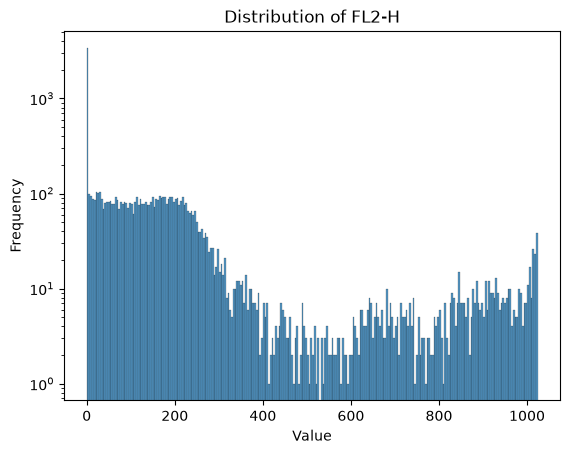

events                         9936.000000
live                           9854.000000
live_pct                         99.174718
recipient                      9461.000000
recipient_pct                    96.011772
donor                             4.000000
donor_pct                         0.040593
cd45_neg                        389.000000
cd45_neg_pct                      3.947635
mac1_pos_recipient              710.000000
mac1_neg_recipient             8751.000000
mac1_pos_recipient_pct            7.504492
mac1_pos_donor                    1.000000
mac1_neg_donor                    3.000000
mac1_pos_donor_pct               25.000000
donor_myeloid_chimerism_pct       0.140647
pi_cutoff                       700.000000
cd45_2_cutoff                   550.000000
cd45_1_cutoff                   450.000000
mac1_cutoff                     500.000000
dtype: float64

027.fcs


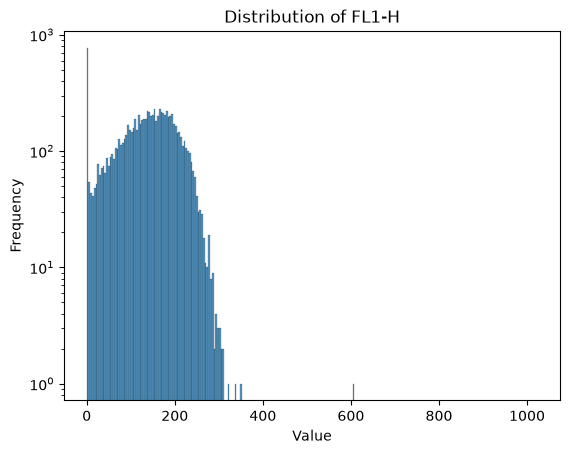

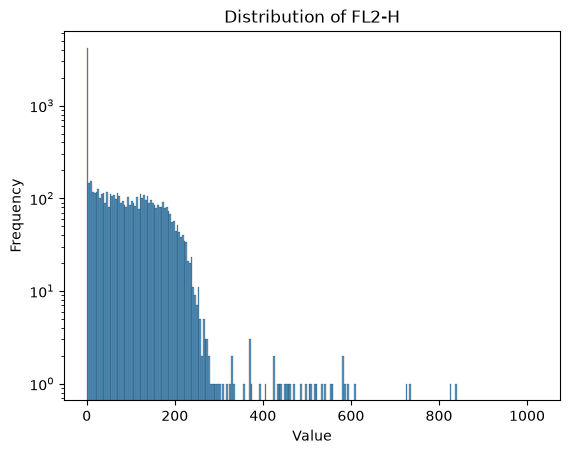

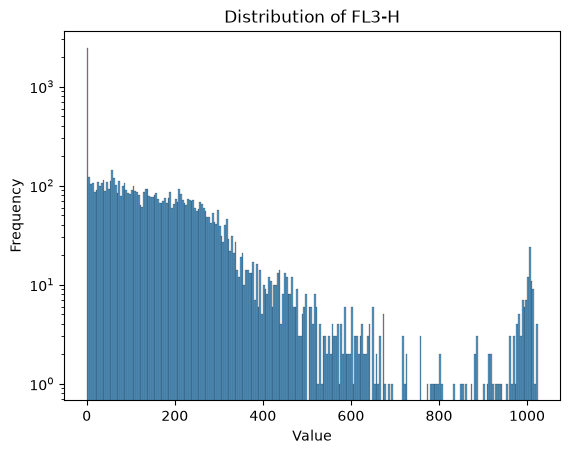

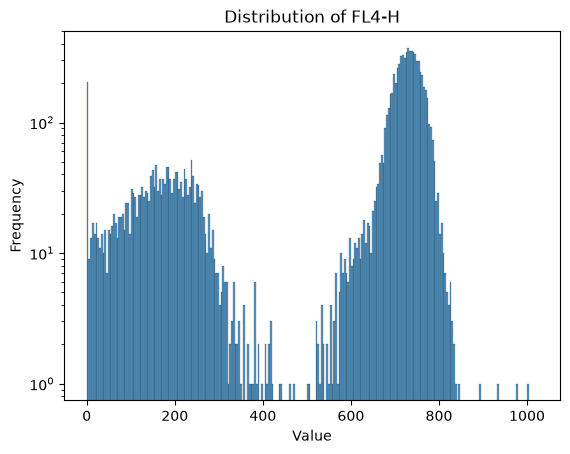

028.fcs


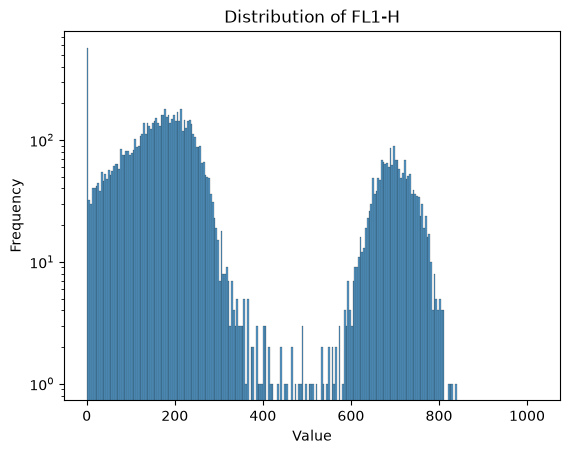

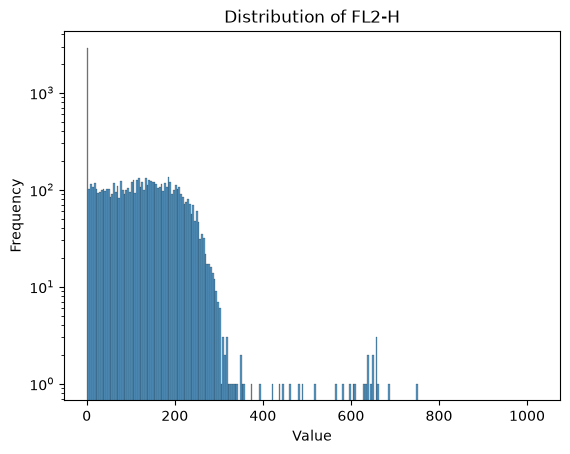

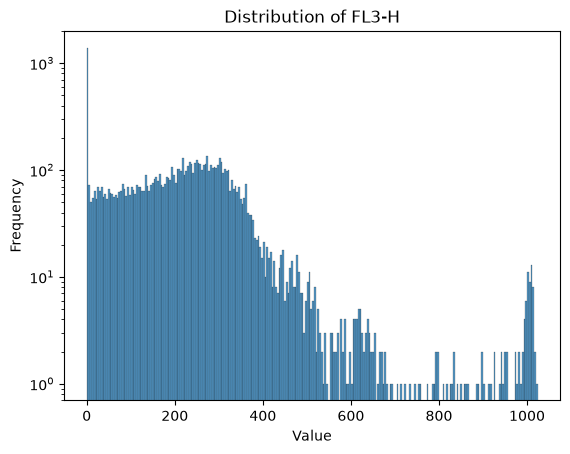

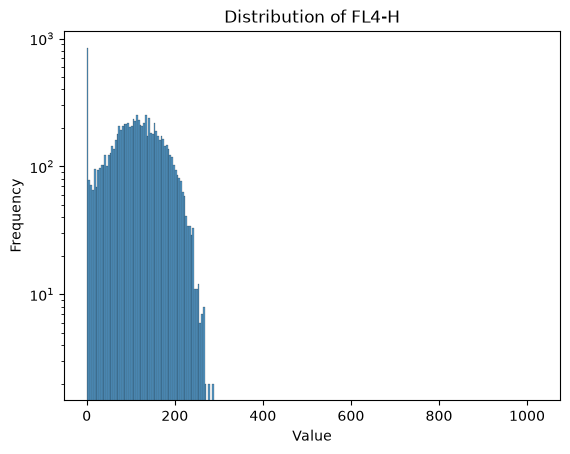

029.fcs


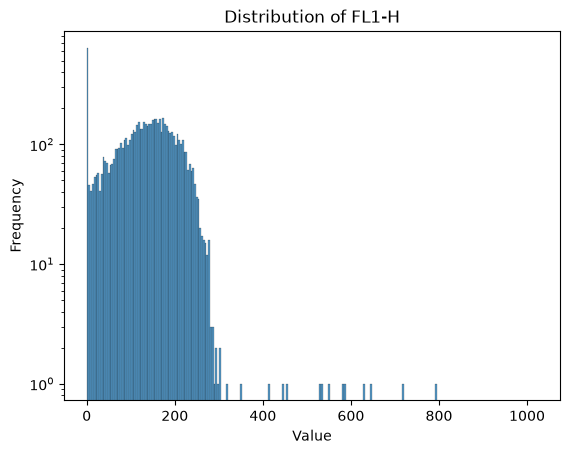

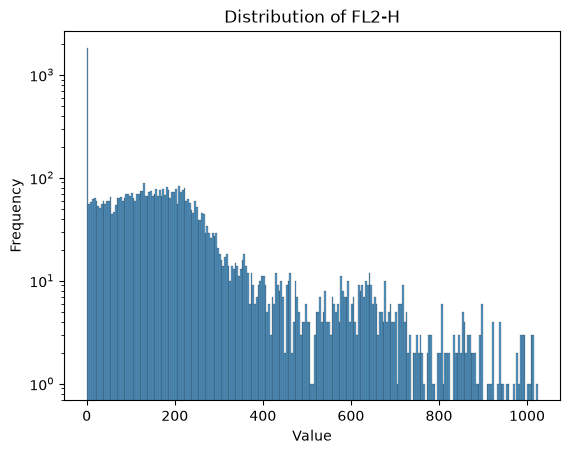

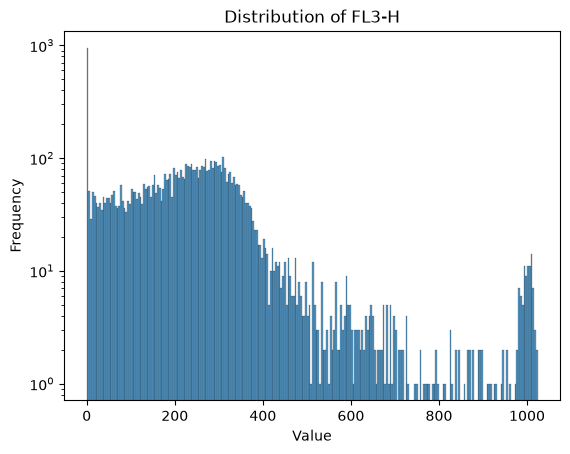

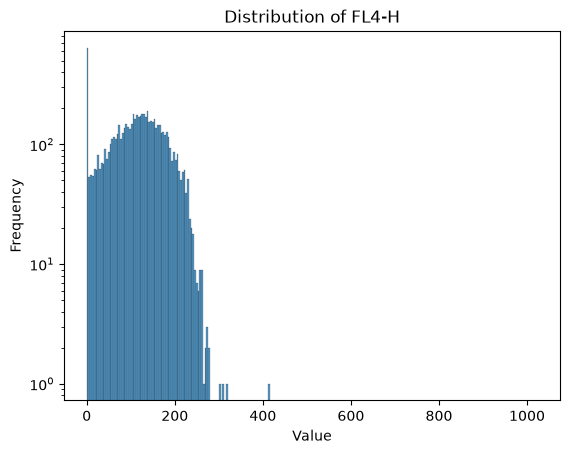

030.fcs


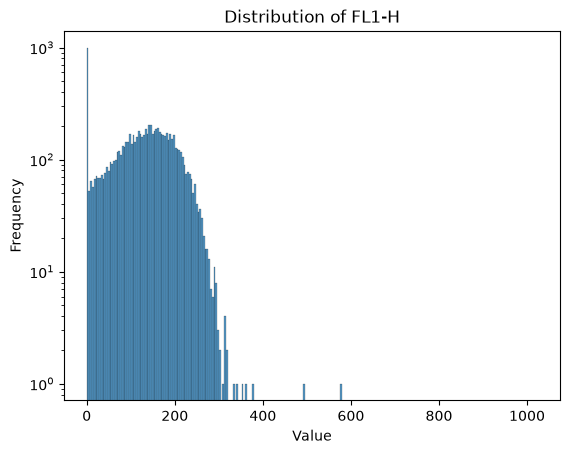

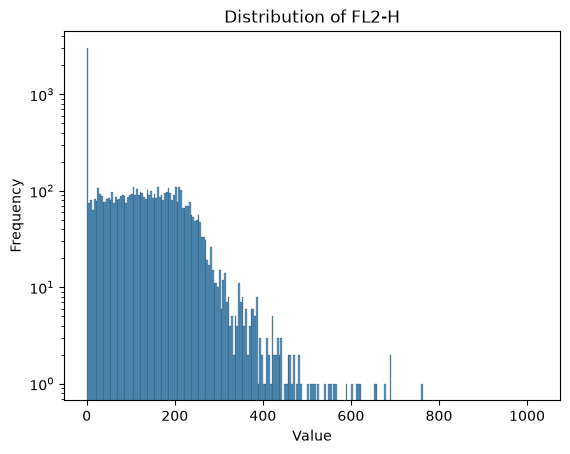

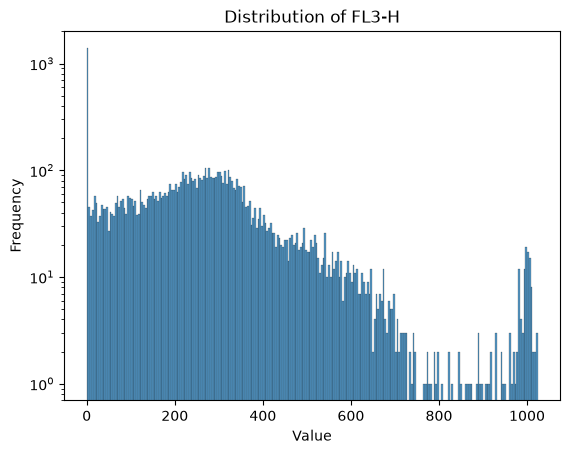

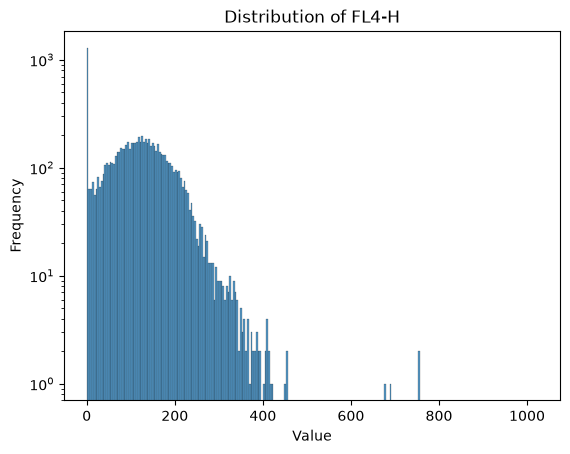

,live_pct,recipient_pct,donor_pct,cd45_neg_pct,mac1_pos_recipient_pct,mac1_pos_donor_pct,donor_myeloid_chimerism_pct
count,26.000000,26.000000,26.000000,26.000000,26.000000,21.000000,26.000000
mean,98.632713,83.135994,11.927674,4.936332,39.541222,33.303534,13.554455
std,0.475922,24.782164,25.677127,5.398391,21.802793,38.776132,28.224005
min,97.178342,15.978847,0.000000,0.377794,2.660754,0.000000,0.000000
25%,98.476929,84.166738,0.010520,1.798538,23.164980,0.000000,0.000000
50%,98.794692,91.797504,0.031507,2.768632,46.998599,10.526316,0.019165
75%,98.944599,96.968137,10.503069,4.616175,55.823763,57.880435,15.016905
max,99.174718,99.622206,82.351721,20.181050,67.172131,100.000000,94.677237


10 of 26 samples have >1% donor cells


In [4]:
# Week 2: gating the FlowCAP-I HSCT dataset
file_location = "data/FlowCAP-I HSCT/001.fcs"
HSCT_sample, HSCT_df = inspect_fcs_file(file_location, verbose=True)
check_spillover_matrix(HSCT_sample)
display(HSCT_df.describe())          # fluorescence max ~1023: already log-scaled, so no transformation

full = [[0, 1023], [0, 1023]]

# Cells vs debris: no events below ~235 on FSC-H, so no debris gate
plot_density(HSCT_df, "FSC-H", "SSC-H", value_range=full)

# Live vs dead (PI), and a check for Mac1 (PE) spillover into the PI channel
plot_histogram(HSCT_df, "FL3-H")
plot_density(HSCT_df, "FL2-H", "FL3-H", value_range=full)
for cutoff in [600, 700, 800, 900]:
    print(f"PI cut-off {cutoff}: {(HSCT_df['FL3-H'] < cutoff).sum()} live cells")

# Recipient (CD45.2) vs the rest
plot_density(HSCT_df, "FL1-H", "FL4-H", value_range=full)

# Donor vs CD45-negative: FL1 within live, CD45.2-low cells, in three transplant samples
for name in ["005.fcs", "022.fcs", "025.fcs"]:
    _, df = inspect_fcs_file(f"data/FlowCAP-I HSCT/{name}")
    cd45_2_low = df[(df["FL3-H"] < 700) & (df["FL4-H"] < 550)]
    print(name)
    plot_histogram(cd45_2_low, "FL1-H")

# Myeloid (Mac1)
plot_histogram(HSCT_df, "FL2-H")

# Gating file 001
summary1 = apply_gating(HSCT_df, 700, 550, 450, 500)
display(pd.Series(summary1))

# Batch: all 30 files with the same cut-offs
final_table = create_table()

# Files 027-030: all four channels, to identify the likely controls
for name in ["027.fcs", "028.fcs", "029.fcs", "030.fcs"]:
    _, df = inspect_fcs_file(f"data/FlowCAP-I HSCT/{name}")
    print(name)
    for channel in ["FL1-H", "FL2-H", "FL3-H", "FL4-H"]:
        plot_histogram(df, channel)

controls = ["027.fcs", "028.fcs", "029.fcs", "030.fcs"]
final_table["likely_control"] = final_table["file"].isin(controls)
final_table.to_csv("results/hsct_gating_summary.csv", index=False)   # re-save with the new column

# Summary of the 26 transplant samples
samples = final_table[~final_table["likely_control"]]
display(samples.filter(like="_pct").describe())
print((samples["donor_pct"] > 1).sum(), "of", len(samples), "samples have >1% donor cells")

In [5]:
# Week 3: validating the gating against expert labels
# Expert labels exist for 4 samples (005, 006, 009, 012), via the R package ks
subject_to_file = {5: "005.fcs", 6: "006.fcs", 9: "009.fcs", 12: "012.fcs"}

# Rename the ks columns to the FCS channel names, so both use the same names
ks_to_fl = {"FITC.CD45.1": "FL1-H", "PE.Ly65Mac1": "FL2-H",
            "PI.LiveDead": "FL3-H", "APC.CD45.2": "FL4-H"}
fl_cols = list(ks_to_fl.values())
author_df = pd.read_csv("data/hsct_ks_labels.csv").rename(columns=ks_to_fl)

# Attach each subject's labels to its own file, after checking every row matches
all_dataframes = []
for subject, file_name in subject_to_file.items():
    _, df = inspect_fcs_file(f"data/FlowCAP-I HSCT/{file_name}")
    subject_rows = author_df[author_df["subject"] == subject].reset_index(drop=True)

    assert len(subject_rows) == len(df), f"{file_name}: different number of events"
    assert np.allclose(subject_rows[fl_cols].to_numpy(), df[fl_cols].to_numpy()), \
        f"{file_name}: values don't match"
    print(f"{file_name}: {len(df)} events, identical values in the same order")

    df["expert_label"] = subject_rows["label"].to_numpy()       # attached by position
    df["my_label"] = assign_labels(df, 700, 550, 450, 500)       # same gates as Week 2
    df["file"] = file_name
    all_dataframes.append(df)

labelled = pd.concat(all_dataframes, ignore_index=True)
assert (labelled["my_label"] != "unassigned").all(), "some events fell outside every gate"

# What each expert class looks like, file by file (median values and cell count)
for file_name, part in labelled.groupby("file"):
    print(file_name)
    profile = part.groupby("expert_label")[fl_cols].median().round(0)
    profile["cells"] = part["expert_label"].value_counts().sort_index()
    display(profile)

# Cross-tables and agreement scores, file by file
all_scores = []
for file_name, part in labelled.groupby("file"):
    tab = pd.crosstab(part["my_label"], part["expert_label"])
    print(f"=== {file_name} ===")
    display(tab)
    scores = score_crosstab(tab)
    scores.insert(0, "file", file_name)
    all_scores.append(scores)

score_table = pd.concat(all_scores, ignore_index=True)
score_table.to_csv("results/hsct_validation_scores.csv", index=False)
display(score_table.round(3))

valid = score_table[score_table["note"] == ""]
print(f"F-measure across {len(valid)} populations: "
      f"min {valid['f_measure'].min():.3f}, max {valid['f_measure'].max():.3f}, "
      f"median {valid['f_measure'].median():.3f}")

005.fcs: 9637 events, identical values in the same order
006.fcs: 9783 events, identical values in the same order
009.fcs: 9780 events, identical values in the same order
012.fcs: 9928 events, identical values in the same order
005.fcs


,FL1-H,FL2-H,FL3-H,FL4-H,cells
expert_label,,,,,
0,454.0,0.0,550.0,80.0,514
1,148.0,45.0,78.0,726.0,1702
2,616.0,123.0,162.0,172.0,6887
3,577.0,874.0,0.0,212.0,533
4,448.0,1022.0,667.0,687.0,1


006.fcs


,FL1-H,FL2-H,FL3-H,FL4-H,cells
expert_label,,,,,
0,521.0,129.0,542.0,146.0,614
1,612.0,894.0,0.0,231.0,795
2,162.0,57.0,77.0,747.0,1430
3,653.0,132.0,154.0,183.0,6944


009.fcs


...

expert_label,0,1,2,3,4
my_label,,,,,
CD45-negative,75,9,6,1,4
dead,113,0,0,0,0
donor Mac1+,5,0,0,1060,0
donor Mac1-,10,0,0,3,762
recipient Mac1+,66,0,3392,0,0
recipient Mac1-,89,4168,17,0,0


=== 012.fcs ===


expert_label,0,1,2,3,4
my_label,,,,,
CD45-negative,168,2,6,0,2
dead,99,0,1,0,0
donor Mac1+,11,0,0,0,511
donor Mac1-,27,0,0,760,0
recipient Mac1+,90,3954,0,0,0
recipient Mac1-,124,2,4171,0,0


,file,expert_class,my_group,expert_cells,precision,recall,f_measure,note
0,005.fcs,1,recipient Mac1-,1702,0.969,1.000,0.984,
1,005.fcs,2,donor Mac1-,6887,0.976,0.995,0.986,
2,005.fcs,3,donor Mac1+,533,0.957,0.957,0.957,
3,005.fcs,4,recipient Mac1+,1,0.021,1.000,0.041,too few cells to score
4,006.fcs,1,donor Mac1+,795,0.937,0.985,0.960,
5,006.fcs,2,recipient Mac1-,1430,0.957,1.000,0.978,
6,006.fcs,3,donor Mac1-,6944,0.974,0.996,0.985,
7,009.fcs,1,recipient Mac1-,4177,0.975,0.998,0.986,
8,009.fcs,2,recipient Mac1+,3415,0.981,0.993,0.987,
9,009.fcs,3,donor Mac1+,1064,0.995,0.996,0.996,


F-measure across 14 populations: min 0.957, max 0.996, median 0.985
